# Final Project Submission

## Python 2

## Jean Chen

See Table of Contents for navigation

### 1. Data Import

- Import the necessary libraries (**pandas, matplotlib.pyplot, seaborn, numpy**, and **scipy.stats**)
- Read the CSV file (marketing_data.csv) using `pd.read_csv()` and store it in a DataFrame (**data**)
- Print a snapshot of the data (**data.head()**) and check the data types and missing values (**data.info()**)


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats

In [2]:
data = pd.read_csv('marketing_data.csv')

In [3]:
data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   2240 non-null   int64 
 1   Year_Birth           2240 non-null   int64 
 2   Education            2240 non-null   object
 3   Marital_Status       2240 non-null   object
 4    Income              2216 non-null   object
 5   Kidhome              2240 non-null   int64 
 6   Teenhome             2240 non-null   int64 
 7   Dt_Customer          2240 non-null   object
 8   Recency              2240 non-null   int64 
 9   MntWines             2240 non-null   int64 
 10  MntFruits            2240 non-null   int64 
 11  MntMeatProducts      2240 non-null   int64 
 12  MntFishProducts      2240 non-null   int64 
 13  MntSweetProducts     2240 non-null   int64 
 14  MntGoldProds         2240 non-null   int64 
 15  NumDealsPurchases    2240 non-null   int64 
 16  NumWeb

<div style="color: #0022aa; background: #ffffcc;">
    <ul>
        <li>Income is missing in 24 entries</li>
    </ul>
</div>

### 2. Investigate Variables

- Check variables like **Dt_Customer** and **Income** to ensure they are imported correctly
- Convert the **income** column to a float by removing '$' and ',' and using `astype('float')`
- Convert the **Dt_Customer** column to a datetime object using `pd.to_datetime()`


In [5]:
data.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', ' Income ',
       'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines',
       'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Response', 'Complain', 'Country'],
      dtype='object')

In [6]:
# Removing extra whitespaces from Income column

data.rename(columns={' Income ': 'Income'}, inplace=True)

In [7]:
# Checking data type of Dt_Customer

data['Dt_Customer'].dtype

dtype('O')

In [8]:
# Dt_Customer data type is incorrect. The type is object and should be date/time.

# Changing data type of the column

In [9]:
# Checking data type of Income

data['Income'].dtype

dtype('O')

In [10]:
# Income data type is incorrect. The type is object and should be integer or float.

# Checking for NaNs

# Change NaNs to zeroes

### 3. Missing Value Imputation
- Check for missing values using `data.isnull().sum()`
- Clean the **marital_status** and **education** categories (e.g., combining similar categories)
- Impute missing **income** values based on similar **education** and **marital_status** categories' average incomes


#### 3.01 Cleaning Income

In [12]:
# Cleaning income column

data['Income'] = data['Income'].str.replace('$', '').str.replace(',', '').str.strip()

In [13]:
# Converting to float

data['Income'] = data['Income'].astype(float)

In [14]:
# Checking cleaning and conversion

data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,84835.0,0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,57091.0,0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,67267.0,0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,32474.0,1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,21474.0,1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP


#### 3.02 Cleaning Dt_Customer (dates)

In [15]:
# Changing data type from string to datetime

data['Dt_Customer'] = pd.to_datetime(data['Dt_Customer'], format='%m/%d/%y')

In [16]:
# Checking if data type was changed

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2240 non-null   int64         
 1   Year_Birth           2240 non-null   int64         
 2   Education            2240 non-null   object        
 3   Marital_Status       2240 non-null   object        
 4   Income               2216 non-null   float64       
 5   Kidhome              2240 non-null   int64         
 6   Teenhome             2240 non-null   int64         
 7   Dt_Customer          2240 non-null   datetime64[ns]
 8   Recency              2240 non-null   int64         
 9   MntWines             2240 non-null   int64         
 10  MntFruits            2240 non-null   int64         
 11  MntMeatProducts      2240 non-null   int64         
 12  MntFishProducts      2240 non-null   int64         
 13  MntSweetProducts     2240 non-nul

In [17]:
# Double checking type change

data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,...,2,7,1,0,0,0,0,1,0,SP


#### 3.1 Check for missing values

In [18]:
data.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Response                0
Complain                0
Country                 0
dtype: int64

#### 3.2 Cleaning Marital_Status

In [19]:
data['Marital_Status'].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
YOLO          2
Absurd        2
Name: count, dtype: int64

<div style="color: #0022aa; background: #ffffcc;">
    <ul>
        <li>Creating new column with "Married" and "Together" mapped to "Partnered"</li>
        <li>Also with "Single", "Divorced", "Widow", "Alone", "YOLO", and "Absurd" mapped to "Unpartnered"</li>
    </ul>
</div>

In [20]:
def replace(value):
    if value == "Married":
        value = "Partnered"
    elif value == "Together":
        value = "Partnered"
    elif value == "Single":
        value = "Unpartnered"
    elif value == "Divorced":
        value = "Unpartnered"
    elif value == "Widow":
        value = "Unpartnered"
    elif value == "Alone":
        value = "Unpartnered"
    elif value == "YOLO":
        value = "Unpartnered"
    elif value == "Absurd":
        value = "Unpartnered"
    return value

data['Marital_Status'].map(replace).value_counts()

Marital_Status
Partnered      1444
Unpartnered     796
Name: count, dtype: int64

In [21]:
data['New_Marital_Status'] = data['Marital_Status'].map(replace)

In [22]:
data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country,New_Marital_Status
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,...,1,0,0,0,0,0,1,0,SP,Unpartnered
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,...,5,0,0,0,0,1,1,0,CA,Unpartnered
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,...,2,0,0,0,0,0,0,0,US,Partnered
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,...,7,0,0,0,0,0,0,0,AUS,Partnered
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,...,7,1,0,0,0,0,1,0,SP,Unpartnered


#### 3.3 Cleaning Education

In [23]:
data['Education'].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

<div style="color: #0022aa; background: #ffffcc;">
    <ul>
        <li>Combining "2n Cycle" and Master</li>
</ul>
</div>

In [24]:
data['New_Education'] = data['Education'].replace('2n Cycle', 'Master')

In [25]:
data['New_Education'].value_counts()

New_Education
Graduation    1127
Master         573
PhD            486
Basic           54
Name: count, dtype: int64

In [26]:
data['Country'].value_counts()

Country
SP     1095
SA      337
CA      268
AUS     160
IND     148
GER     120
US      109
ME        3
Name: count, dtype: int64

In [27]:
data.groupby(['Education','Country'],as_index=False)["ID"].count()

,Education,Country,ID
0,2n Cycle,AUS,9
1,2n Cycle,CA,24
2,2n Cycle,GER,20
3,2n Cycle,IND,21
4,2n Cycle,SA,25
5,2n Cycle,SP,97
6,2n Cycle,US,7
7,Basic,AUS,4
8,Basic,CA,7
9,Basic,GER,2


In [28]:
data.groupby(['Country','Education'],as_index=False)["ID"].count()

,Country,Education,ID
0,AUS,2n Cycle,9
1,AUS,Basic,4
2,AUS,Graduation,85
3,AUS,Master,32
4,AUS,PhD,30
5,CA,2n Cycle,24
6,CA,Basic,7
7,CA,Graduation,133
8,CA,Master,49
9,CA,PhD,55


#### 3.4 Impute missing Income data

In [29]:
# Calculate the average income by marriage and education group

meanIncome = data.groupby(['New_Marital_Status', 'New_Education'])['Income'].transform('mean')

# Fill missing income values with the calculated means

data['Income'] = data['Income'].fillna(meanIncome)

In [30]:
data['Income']

0       84835.0
1       57091.0
2       67267.0
3       32474.0
4       21474.0
         ...   
2235    66476.0
2236    31056.0
2237    46310.0
2238    65819.0
2239    94871.0
Name: Income, Length: 2240, dtype: float64

In [31]:
# Re-check for blank cells

data.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Response               0
Complain               0
Country                0
New_Marital_Status     0
New_Education          0
dtype: int64


### 4. Create Variables
- Calculate the **age** of customers based on **year_birth**
- Calculate **spending** as the sum of spending columns (**mntwines,
mntfruits**, etc.)
- Calculate **children_count** as the sum of **kidhome** and **teenhome**.
- Create a binary variable **has_children** indicating if a customer has children
- Derive **total_purchases** from the sum of purchase columns


#### 4.1 Calculate _age_

In [32]:
# Create a new column for age

from datetime import datetime, date

today = date.today()
data['age'] = today.year - data['Year_Birth']

#### 4.2 Calculate _spending_

In [33]:
# Create a new column for spending

data['spending'] = data[['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']].sum(axis=1)

#### 4.3 Calculate _children_count_

In [34]:
# Create a new column for number of children

data['children_count'] = data[['Kidhome', 'Teenhome']].sum(axis=1)

#### 4.4 Create binary variable _has_children_

In [35]:
# Create a new column for whether a family has children

data['has_children'] = data['children_count'] > 0

#### 4.5 Derive _total_purchases_

In [36]:
# Create a new column for total purchases

data['total_purchases'] = data[['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum(axis=1)

In [37]:
# Check the new columns

data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Response,Complain,Country,New_Marital_Status,New_Education,age,spending,children_count,has_children,total_purchases
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,...,1,0,SP,Unpartnered,Graduation,55,1190,0,False,15
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,...,1,0,CA,Unpartnered,Graduation,64,577,0,False,18
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,...,0,0,US,Partnered,Graduation,67,251,1,True,11
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,...,0,0,AUS,Partnered,Graduation,58,11,2,True,4
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,...,1,0,SP,Unpartnered,Graduation,36,91,1,True,8


### 5. Box Plots and Histograms
- Plot box plots and histograms for numerical variables (**income, spending, age, total_purchases**) to understand their distributions and identify outliers
- Perform outlier treatment by capping the outliers to the upper and lower limits

#### 5.1 Income

In [44]:
data['Income'].mean()

np.float64(52252.797256147365)

In [45]:
data['Income'].median()

51533.0

<Axes: title={'center': ' Income Histogram'}, ylabel='Frequency'>

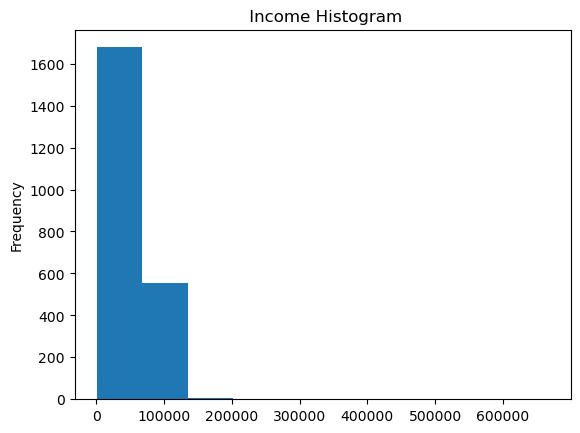

In [80]:
data['Income'].plot(kind='hist',title=' Income Histogram')

<Axes: title={'center': 'Income Box Plot'}>

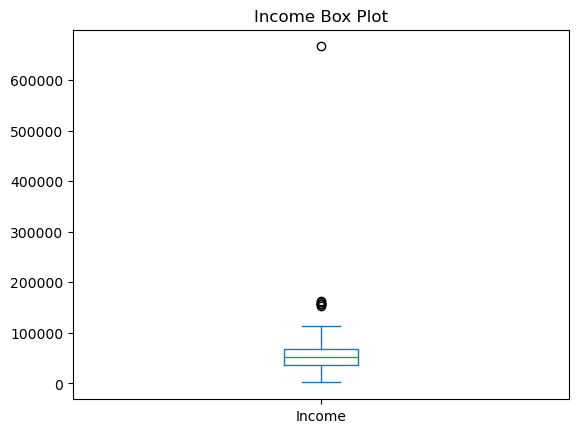

In [81]:
data['Income'].plot(kind='box',title='Income Box Plot')

<Axes: xlabel='Income', ylabel='Education'>

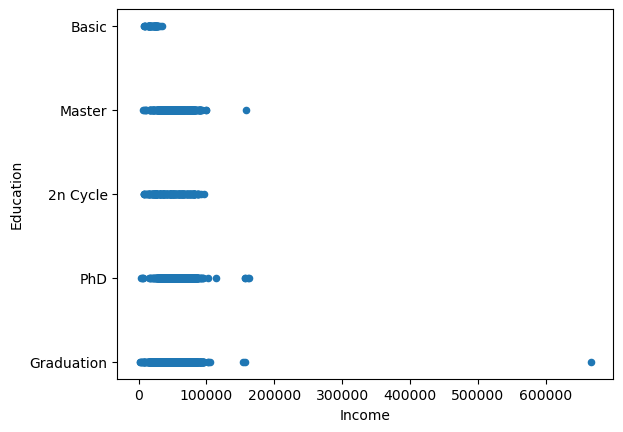

In [48]:
data.plot(x='Income',y='Education',kind='scatter',legend=True)

<Axes: title={'center': 'Histogram'}, ylabel='Frequency'>

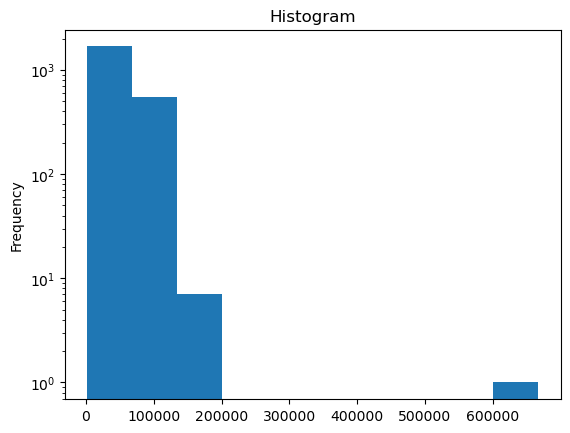

In [49]:
# Plot on log scale to examine the outlier

data['Income'].plot(kind='hist',title='Histogram', log=True)

<div style="color: #0022aa; background: #ffffcc;">
    <ul>
        <li>There is an outlier whose income is greater than \$600,000. </li>
        <li>Creating a new column where income is capped to an upper limit of \$200,000.</li>
    </ul>
</div>

<Axes: xlabel='Cap_Income', ylabel='Education'>

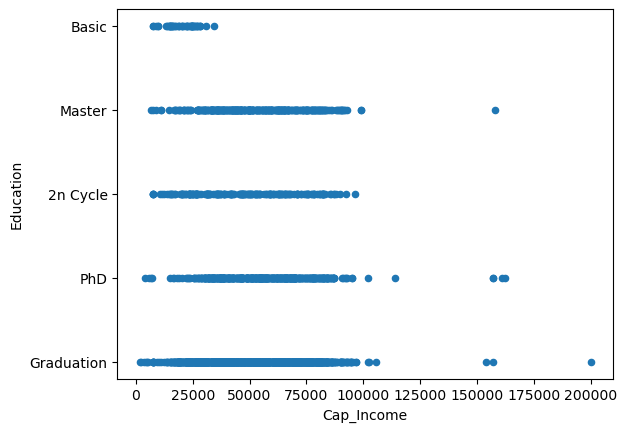

In [50]:
# Creating capped income column

data['Cap_Income'] = np.minimum(data['Income'], 200000)

data.plot(x='Cap_Income',y='Education',kind='scatter',legend=True)

#### 5.2 Spending

<Axes: title={'center': 'Spending Box Plot'}>

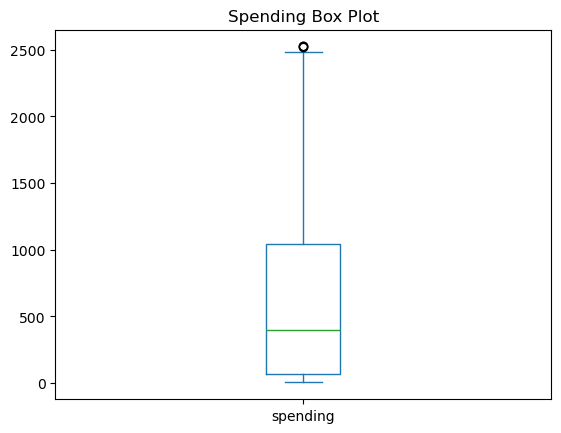

In [82]:
data['spending'].plot(kind='box',title='Spending Box Plot')

<Axes: title={'center': 'Spending Histogram'}, ylabel='Frequency'>

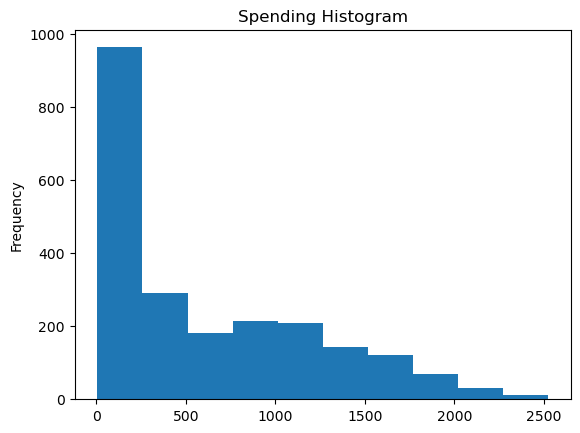

In [83]:
data['spending'].plot(kind='hist',title='Spending Histogram')

#### 5.3 Age

<Axes: title={'center': 'Age Box Plot'}>

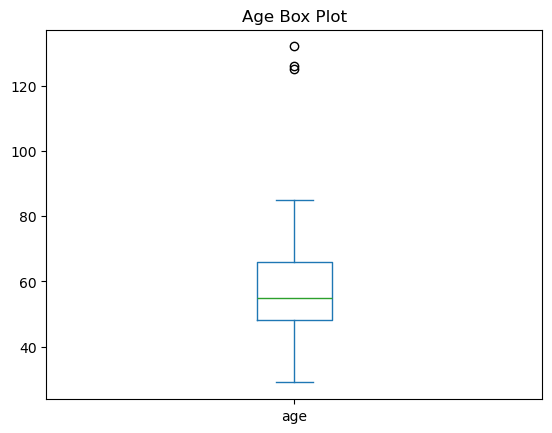

In [84]:
data['age'].plot(kind='box',title='Age Box Plot')

<Axes: title={'center': 'Age Histogram'}, ylabel='Frequency'>

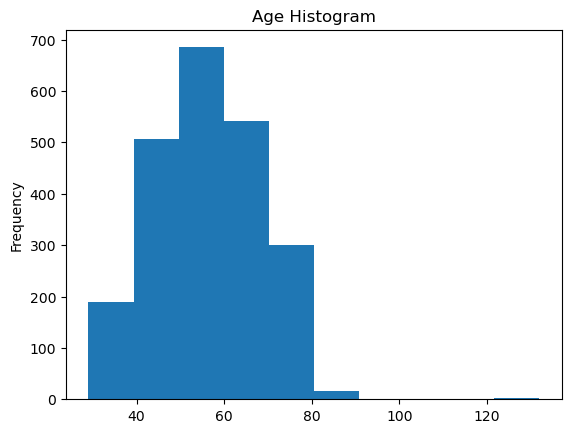

In [85]:
data['age'].plot(kind='hist',title='Age Histogram')

#### 5.4 Total Purchases

<Axes: title={'center': 'Total Purchases Box Plot'}>

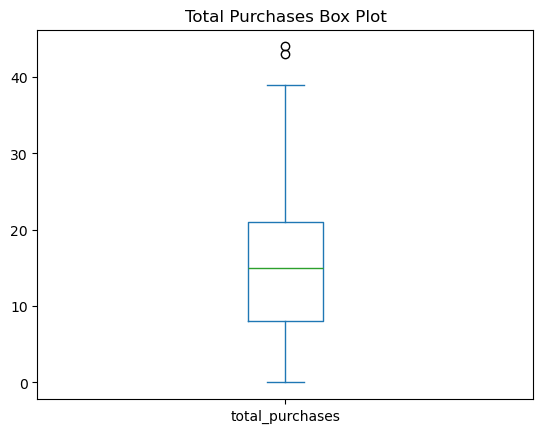

In [86]:
data['total_purchases'].plot(kind='box',title='Total Purchases Box Plot')

<Axes: title={'center': 'Total Purchases Histogram'}, ylabel='Frequency'>

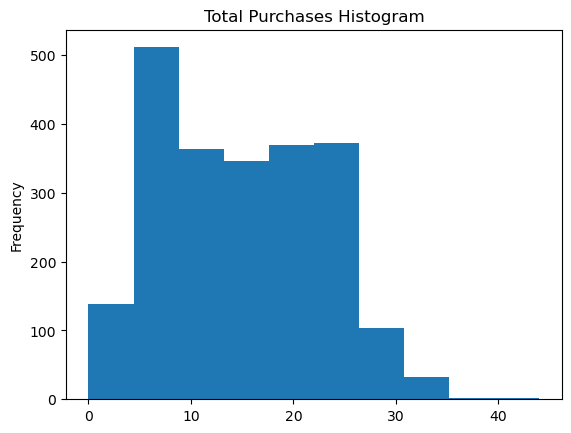

In [87]:
data['total_purchases'].plot(kind='hist',title='Total Purchases Histogram')


### 6. Encoding
- Use ordinal encoding for the **education** column
- Use one-hot encoding for the **country** and **marital_status** columns


#### 6.1 Education

<div style="color: #0022aa; background: #ffffcc;">
    <ul>
        <li>Create ordinal encoding for education as follows:
            <ul>
                <li>basic = Basic = 0</li>
                <li>graduation = 1st cycle (European system) = 1</li>
                <li>2n cycle + master = 2nd cycle = 2</li>
                <li>phd = 3rd cycle = 3</li>
            </ul>
        </li>
    </ul>
</div>

In [51]:
def replace(value):
    if value == "Basic":
        value = "0"
    elif value == "Graduation":
        value = "1"
    elif value == "Master":
        value = "2"
    elif value == "PhD":
        value = "3"
    return value

data['New_Education'].map(replace).value_counts()

New_Education
1    1127
2     573
3     486
0      54
Name: count, dtype: int64

In [52]:
data['Ordinal_Education'] = data['New_Education'].map(replace)

data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Country,New_Marital_Status,New_Education,age,spending,children_count,has_children,total_purchases,Cap_Income,Ordinal_Education
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,...,SP,Unpartnered,Graduation,55,1190,0,False,15,84835.0,1
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,...,CA,Unpartnered,Graduation,64,577,0,False,18,57091.0,1
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,...,US,Partnered,Graduation,67,251,1,True,11,67267.0,1
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,...,AUS,Partnered,Graduation,58,11,2,True,4,32474.0,1
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,...,SP,Unpartnered,Graduation,36,91,1,True,8,21474.0,1


#### 6.2 One-Hot Country

In [53]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output = False)

encoded_array = encoder.fit_transform(data['Country'].values.reshape(-1,1))

encoded_df = pd.DataFrame(encoded_array, columns = encoder.get_feature_names_out(['Country']))

encoded_df = pd.concat([data, encoded_df], axis=1)

print(encoder.get_feature_names_out(['Country']))

['Country_AUS' 'Country_CA' 'Country_GER' 'Country_IND' 'Country_ME'
 'Country_SA' 'Country_SP' 'Country_US']


In [54]:
data.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Response', 'Complain', 'Country', 'New_Marital_Status',
       'New_Education', 'age', 'spending', 'children_count', 'has_children',
       'total_purchases', 'Cap_Income', 'Ordinal_Education'],
      dtype='object')

In [55]:
column_names = encoder.get_feature_names_out(['Country'])
print(column_names)

['Country_AUS' 'Country_CA' 'Country_GER' 'Country_IND' 'Country_ME'
 'Country_SA' 'Country_SP' 'Country_US']


In [56]:
encoder.get_feature_names_out()

array(['x0_AUS', 'x0_CA', 'x0_GER', 'x0_IND', 'x0_ME', 'x0_SA', 'x0_SP',
       'x0_US'], dtype=object)

In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Define the transformer

transformer = ColumnTransformer(
    transformers=[
        ('country_encoder', OneHotEncoder(), ['Country'])  # This specifies the column name to transform
    ]
)

# Fit and transform

transformed_data = transformer.fit_transform(data)
print(transformed_data)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2240 stored elements and shape (2240, 8)>
  Coords	Values
  (0, 6)	1.0
  (1, 1)	1.0
  (2, 7)	1.0
  (3, 0)	1.0
  (4, 6)	1.0
  (5, 6)	1.0
  (6, 2)	1.0
  (7, 6)	1.0
  (8, 7)	1.0
  (9, 3)	1.0
  (10, 7)	1.0
  (11, 6)	1.0
  (12, 3)	1.0
  (13, 1)	1.0
  (14, 6)	1.0
  (15, 6)	1.0
  (16, 6)	1.0
  (17, 6)	1.0
  (18, 1)	1.0
  (19, 1)	1.0
  (20, 5)	1.0
  (21, 3)	1.0
  (22, 2)	1.0
  (23, 6)	1.0
  (24, 3)	1.0
  :	:
  (2215, 6)	1.0
  (2216, 7)	1.0
  (2217, 7)	1.0
  (2218, 7)	1.0
  (2219, 1)	1.0
  (2220, 5)	1.0
  (2221, 6)	1.0
  (2222, 6)	1.0
  (2223, 6)	1.0
  (2224, 5)	1.0
  (2225, 0)	1.0
  (2226, 6)	1.0
  (2227, 6)	1.0
  (2228, 6)	1.0
  (2229, 6)	1.0
  (2230, 6)	1.0
  (2231, 0)	1.0
  (2232, 6)	1.0
  (2233, 3)	1.0
  (2234, 7)	1.0
  (2235, 7)	1.0
  (2236, 6)	1.0
  (2237, 6)	1.0
  (2238, 3)	1.0
  (2239, 1)	1.0


#### 6.3 One-Hot Marital Status

In [58]:
# Define the transformer

transformer = ColumnTransformer(
    transformers=[
        ('mstatus_encoder', OneHotEncoder(), ['New_Marital_Status'])  # This specifies the column name to transform
    ]
)

# Fit and transform

transformed_data = transformer.fit_transform(data)
print(transformed_data)

[[0. 1.]
 [0. 1.]
 [1. 0.]
 ...
 [0. 1.]
 [1. 0.]
 [1. 0.]]


<div style="color: #0022aa; background: #ffffcc;">
    <ul>
        <li>Write work so far to new file.</li>
    </ul>
</div>

In [59]:
# Write dataframe to new file

data.to_csv('marketing_data_new.csv', index=False)

### 7. Correlation Analysis
- Select a subset of columns for correlation analysis
- Compute the correlation matrix `(new_data\[var_cor\].corr())` and plot a heatmap `(sns.heatmap())`


In [60]:
data.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Response', 'Complain', 'Country', 'New_Marital_Status',
       'New_Education', 'age', 'spending', 'children_count', 'has_children',
       'total_purchases', 'Cap_Income', 'Ordinal_Education'],
      dtype='object')

In [61]:
data['Ordinal_Education'] = data['Ordinal_Education'].astype(int)

#### 7.1 Select subset of columns

<div style="color: #0022aa; background: #ffffcc;">
    <ul>
        <li>Correlation analysis for income vs spending</li>
    </ul>
</div>

#### 7.2 Compute correlation matrix

In [62]:
# Computing correlation matrix

var_cor = ['Ordinal_Education', 'children_count', 'total_purchases']
corr_matrix = data[var_cor].corr()

#### 7.3 Plot a heatmap

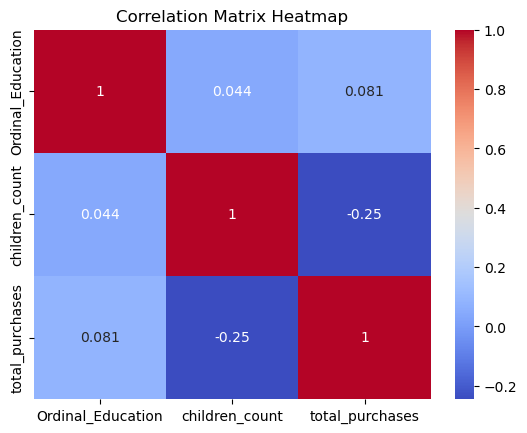

In [63]:
# Plotting heat map

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix Heatmap')
plt.show()

### 8. Hypothesis Testing
- Define and test hypotheses related to customer behavior using statistical tests `(stats.ttest_ind())`


<div style="color: #0022aa; background: #ffffcc;">
<p>
Does the average total spending of consumers differ according to their education level? </br>
Find answer by running a t-test on columns "total_purchases" and "Ordinal_Education". </br>
Null hypothesis: No, spending does not differ according to education level. </br>
Null hypothesis rejection: Spending differs according to education level.
</p>
</div>

In [64]:
t_stat, p_val = stats.ttest_ind(data['spending'], data['Ordinal_Education'])
print(f"t-statistic: {t_stat}, p-value: {p_val}")

t-statistic: 47.47659409839348, p-value: 0.0


<div style="color: #0022aa; background: #ffffcc;">
<p>
The t-statistic result of 47.47 indicates a strong difference in spending amounts between education levels. </br>
It is over 47 standard errors away from that expected in the null hypothesis. </br>
The p-value of 0 indicates that there is 0 probability that the observed differences were due to random chance. </br>
Therefore the null hypothesis can be rejected. Spending does differ according to education level.
</p>
</div>

### 9. Visualization
- Visualize the performance of products (**prod_data**) using a bar plot
- Explore the relationship between **age** and campaign acceptance rate (**acceptedcmp5**) using a bar plot
- Determine the country with the most customers who accepted the last campaign using a bar plot
- Analyze the relationship between **children_count** and **spending** using a strip plot
- Visualize the educational background of customers who complained in the last two years using a bar plot
- Explore the relationship between **income** and **spending** using a scatter plot


#### 9.1 Visualize the performance of products (prod_data) using a bar plot

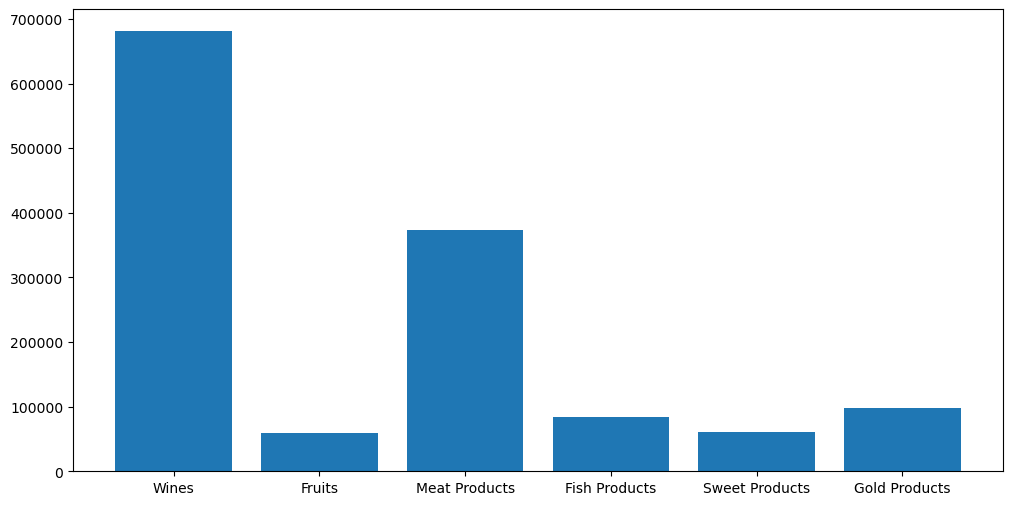

In [66]:
prod_columns = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']

prod_sum = data[prod_columns].sum()

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(prod_sum)), prod_sum.values)

# Label product types
prod_labels = ['Wines', 'Fruits', 'Meat Products', 'Fish Products', 'Sweet Products', 'Gold Products']
plt.xticks(range(len(prod_sum)), prod_labels)

plt.show()

<div style="color: #0022aa; background: #ffffcc;">
    <ul>
        <li>Wines are by far the most popular product</li>
        <li>Meats products are the next most popular, however they are only about half as popular as wines</li>
        <li>Fruits, fish products, sweet products, and gold products all have low popularity</li>
    </ul>
</div>

#### 9.2 Explore the relationship between age and campaign acceptance rate (acceptedcmp5) using a bar plot

In [69]:
# Separate campaign acceptance rates into decades for bar plot

data['age_decade'] = (data['age'] // 10) * 10

decade_acceptance = data.groupby('age_decade')['AcceptedCmp5'].agg(['mean', 'count']).reset_index()
decade_acceptance.columns = ['age_decade', 'acceptance_rate', 'count']

print(decade_acceptance)

   age_decade  acceptance_rate  count
0          20         0.000000      2
1          30         0.133690    187
2          40         0.063241    506
3          50         0.059854    685
4          60         0.058943    492
5          70         0.090909    341
6          80         0.166667     24
7         120         0.500000      2
8         130         0.000000      1


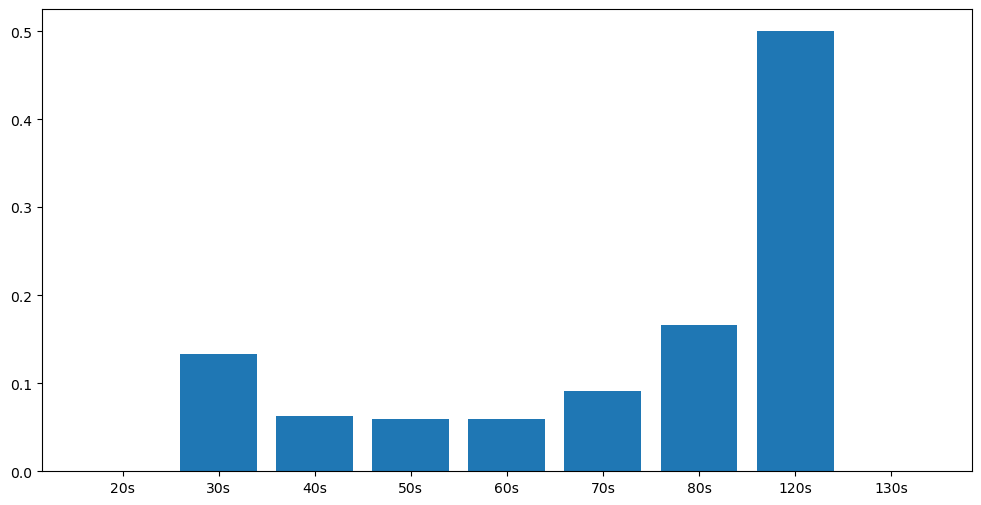

In [70]:
# Create bar chart

plt.figure(figsize=(12, 6))
decade_labels = [str(int(decade)) + 's' for decade in decade_acceptance['age_decade']]
bars = plt.bar(decade_labels, decade_acceptance['acceptance_rate'])

<div style="color: #0022aa; background: #ffffcc;">
<ul>
    <li>Customers in their 30s have the highest acceptance rate at 13.4%</li>
    <li>Middle-aged customers (40s-60s) have lower acceptance rates around 6%</li>
    <li>Acceptance rates rise again for customers in their 70s (9.1%) and 80s (16.7%)</li>
</ul>
</div>

#### 9.3 Determine the country with the most customers who accepted the last campaign using a bar plot

In [71]:
# Calculate acceptance rate for each country

country_acceptance = data.groupby('Country')['AcceptedCmp5'].agg(['mean', 'count']).reset_index()
country_acceptance.columns = ['Country', 'acceptance_rate', 'count']

print(country_acceptance)

  Country  acceptance_rate  count
0     AUS         0.081250    160
1      CA         0.078358    268
2     GER         0.066667    120
3     IND         0.040541    148
4      ME         0.000000      3
5      SA         0.062315    337
6      SP         0.081279   1095
7      US         0.045872    109


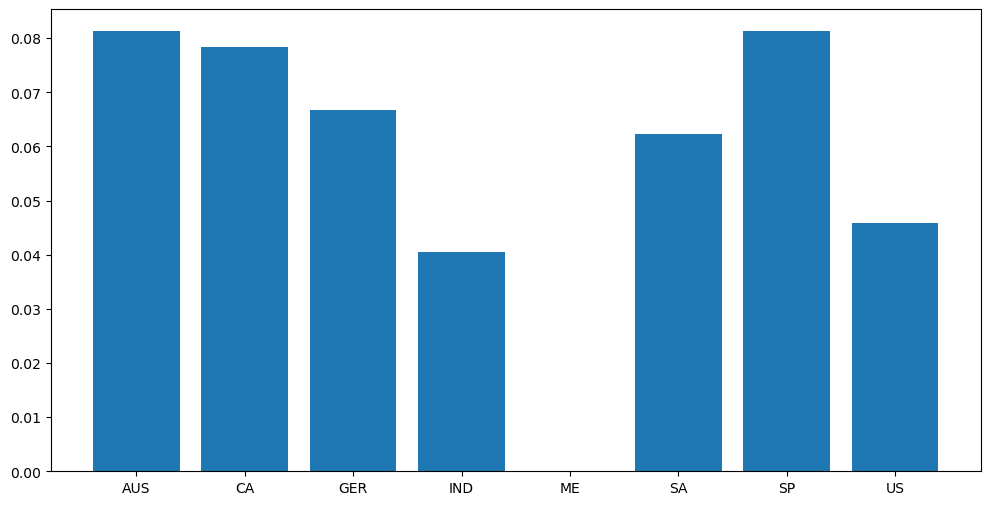

In [72]:
# Create bar chart 

plt.figure(figsize=(12, 6))

bars = plt.bar(country_acceptance['Country'], country_acceptance['acceptance_rate'])
plt.show()

<div style="color: #0022aa; background: #ffffcc;">
<ul>
    <li>Spain (SP) and Australia (AUS) have the highest acceptance rates at 8.1%</li>
    <li>Canada (CA) is next with 7.8%</li>
    <li>Germany (GER) and South Africa (SA) are lower around 6-7%</li>
    <li>United States (US) and India (IND) have the lowest acceptance rates: 4.6% and 4.1%</li>
</ul>
<p>Spain has the largest customer base (1,095 customers), so its 8.1% acceptance rate may be important for determining marketing strategy in the future. Differences between countries suggest that cultural, economic, or regional factors may be influencing the results.</p>
</div>

#### 9.4 Analyze the relationship between children_count and spending using a strip plot

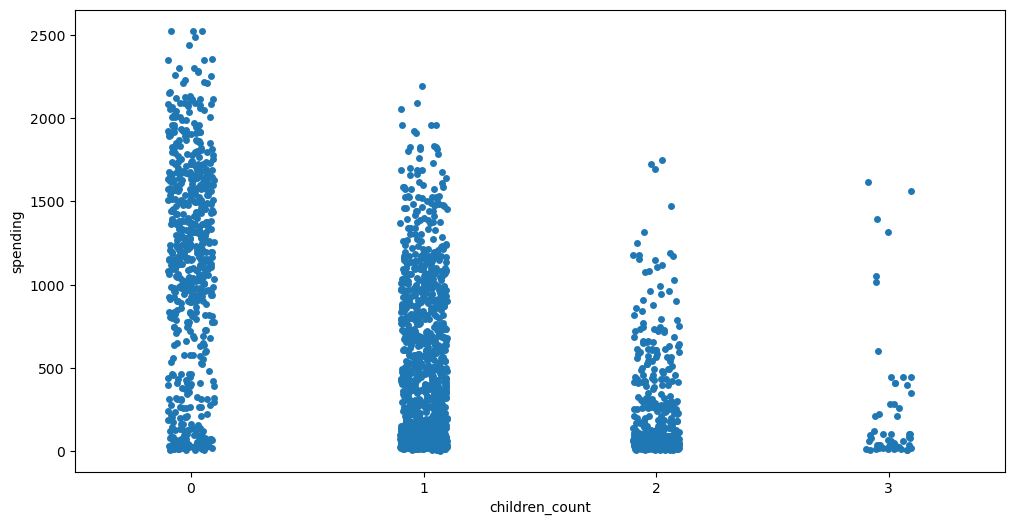

In [73]:
# Create strip plot comparing children_count and spending

plt.figure(figsize=(12, 6))
sns.stripplot(data, x='children_count', y='spending')

plt.show()

<div style="color: #0022aa; background: #ffffcc;">
<ul>
<li>As number of children increases, spending decreases.</li>
</ul>
</div>

#### 9.5 Visualize the educational background of customers who complained in the last two years using a bar plot

In [74]:
# Calculate rate of complaints by education level

education_complain = data.groupby('New_Education')['Complain'].agg(['mean', 'count']).reset_index()
education_complain.columns = ['New_Education', 'complain_rate', 'count']

print(education_complain)

  New_Education  complain_rate  count
0         Basic       0.000000     54
1    Graduation       0.012422   1127
2        Master       0.010471    573
3           PhD       0.002058    486


In [75]:
# Find the years with customer data

data['Dt_Customer'] = pd.to_datetime(data['Dt_Customer'])
data['customer_year'] = data['Dt_Customer'].dt.year
print(data['customer_year'].value_counts().sort_index())

customer_year
2012     494
2013    1189
2014     557
Name: count, dtype: int64


In [76]:
# Filter data for the last two years (2013 and 2014)

past_two_years = data[data['customer_year'].isin([2013, 2014])]

# Calculate complaint rates by education level

education_complain_filtered = past_two_years.groupby('New_Education')['Complain'].agg(['mean', 'count']).reset_index()
education_complain_filtered.columns = ['New_Education', 'complain_rate', 'count']

print(education_complain_filtered)

  New_Education  complain_rate  count
0         Basic       0.000000     33
1    Graduation       0.012528    878
2        Master       0.008772    456
3           PhD       0.000000    379


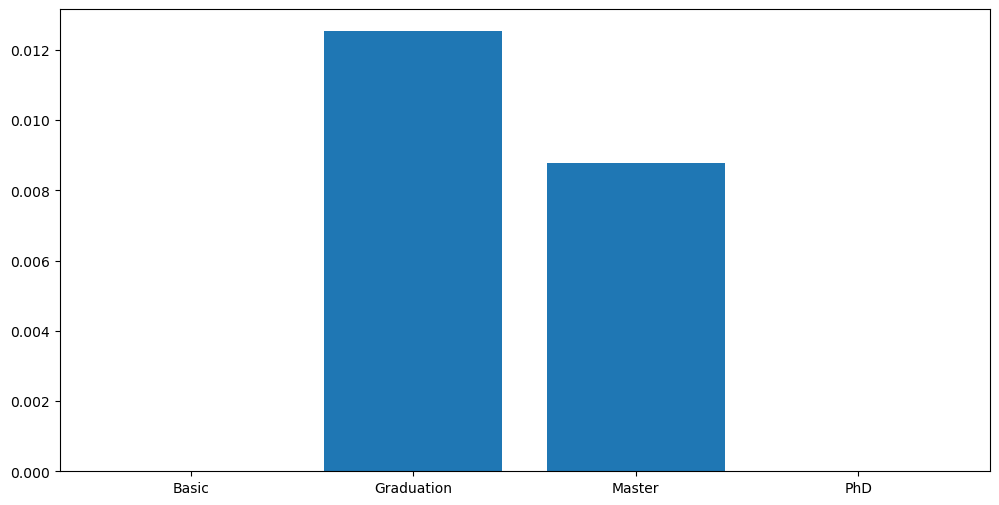

In [77]:
# Create bar chart for complaint rates by education level (past two years only)

plt.figure(figsize=(12, 6))
bars = plt.bar(education_complain_filtered['New_Education'], education_complain_filtered['complain_rate'])

plt.show()

<div style="color: #0022aa; background: #ffffcc;">
    <ul>
        <li>In the last two years of data, only customers with Graduation and Master's degrees filed complaints.</li>
        <li>Basic and PhD education groups had zero complaints.</li>
    </ul>
</div>

#### 9.6 Explore the relationship between income and spending using a scatter plot

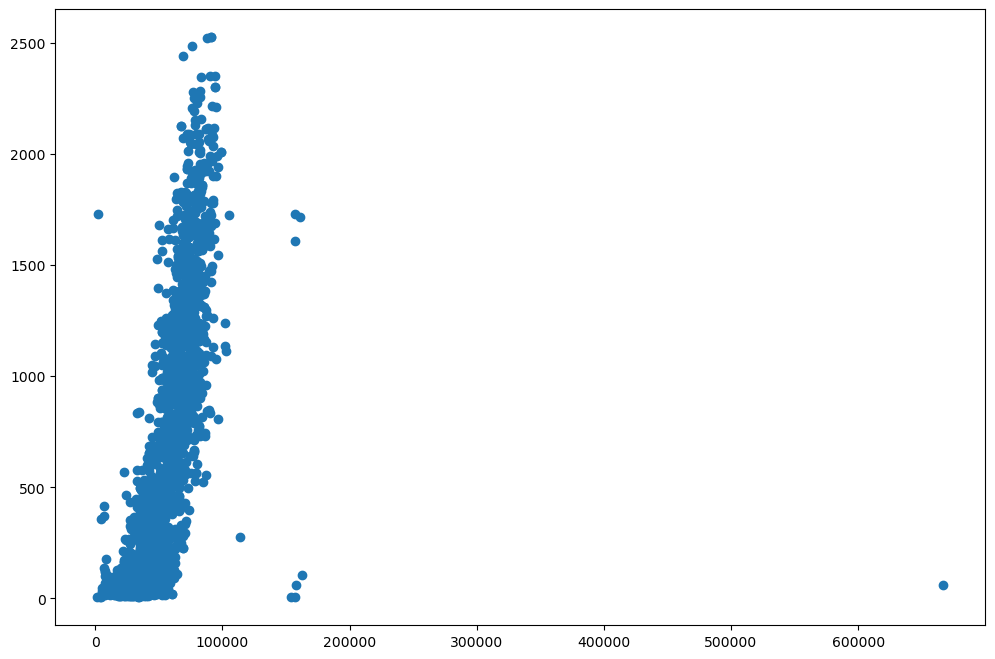

Income vs Spending correlation: 0.6644712157557263


In [78]:
# Create scatter plot comparing Income and spending

plt.figure(figsize=(12, 8))
plt.scatter(data['Income'], data['spending'])

plt.show()

# Add correlation coefficient

correlation = data['Income'].corr(data['spending'])
print("Income vs Spending correlation:", correlation)

<div style="color: #0022aa; background: #ffffcc;">
    <ul>
        <li>There is a strong positive correlation (0.664) between income and spending.</li>
        <li>Customers with higher incomes tend to spend more.</li>
    </ul>
</div>

## End